# Activity 2 — Fill gaps and group similar years

**COM7024 · Lesson 7 · SciPy**  
Real question: How can we estimate missing CO₂ readings and group years by average concentration? Suggested time: 25 minutes.

**How to use:** Run the cells from top to bottom. Every example works with the supplied full dataset.

## Step 0 — Find the data folder

This short setup supports your GitHub layout: `app/L7/` for notebooks and `data/` at the repository root.

In [1]:
from pathlib import Path

# The data folder is at the root of your GitHub repository.
DATA = Path("data")                 # If Jupyter starts at the repository root
if not DATA.exists():
    DATA = Path("../../data")       # If Jupyter starts inside app/L7
if not DATA.exists():
    DATA = Path("../data")          # If notebooks are in a separate folder

print("Data folder:", DATA.resolve())

Data folder: /workspaces/ProgrammongForDA/data


## 1. Load the full dataset

The `co2_ppm` column contains missing readings.

In [2]:
import pandas as pd

df = pd.read_csv(DATA / "MaunaLoa_CO2_Full.csv", parse_dates=["date"])
print("Rows:", len(df))
print("Missing CO2 readings:", df["co2_ppm"].isna().sum())
display(df.head())

Rows: 2284
Missing CO2 readings: 59


,date,co2_ppm
0,1958-03-29,316.1
1,1958-04-05,317.3
2,1958-04-12,317.6
3,1958-04-19,317.5
4,1958-04-26,316.4


## 2. Fill gaps with a straight line

Pandas linear interpolation is a good starting point.

In [3]:
df["linear"] = df["co2_ppm"].interpolate()
print("Missing before:", df["co2_ppm"].isna().sum())
print("Missing after:", df["linear"].isna().sum())

Missing before: 59
Missing after: 0


## 3. Try a SciPy curved interpolator

`CubicSpline` fits smooth curves through the known points. It may overshoot, so smooth does not always mean better.

In [4]:
from scipy.interpolate import CubicSpline

known = df.dropna(subset=["co2_ppm"])
spline = CubicSpline(known.index, known["co2_ppm"])
df["cubic"] = spline(df.index)

## 4. Compare around a real missing reading

Find the first missing row and zoom into nearby weeks.

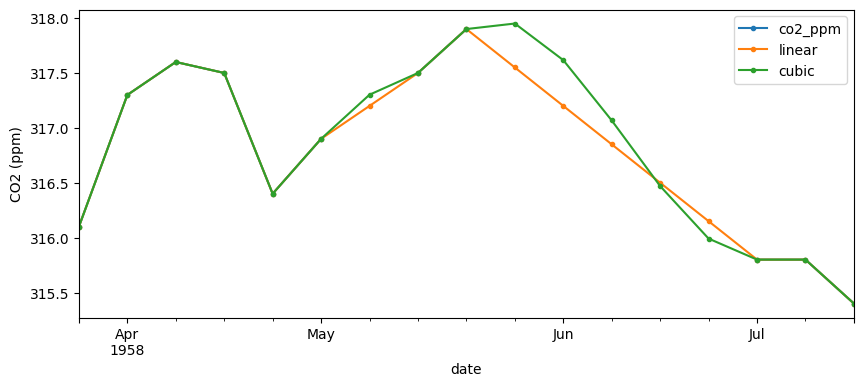

In [5]:
import matplotlib.pyplot as plt

first_gap = df["co2_ppm"].isna().idxmax()
window = df.iloc[max(0, first_gap-10):first_gap+11]
window.plot(x="date", y=["co2_ppm", "linear", "cubic"],
            figsize=(10, 4), marker=".")
plt.ylabel("CO2 (ppm)")
plt.show()

## 5. Find each year’s average

Group the complete weekly dataset into yearly averages.

In [6]:
annual = df.groupby(df["date"].dt.year)["linear"].mean()
print(annual.head())

date
1958    315.187500
1959    315.957692
1960    316.860377
1961    317.592308
1962    318.451923
Name: linear, dtype: float64


## 6. Cluster the yearly averages

`kmeans2` groups similar values. We choose **2 groups** to keep the example simple.

In [7]:
from scipy.cluster.vq import kmeans2

values = annual.to_numpy().reshape(-1, 1)
centres, groups = kmeans2(values, 2, minit="++", seed=7)

result = pd.DataFrame({"year": annual.index,
                       "mean_ppm": annual.values,
                       "group": groups})
print(result.head(10))

   year    mean_ppm  group
0  1958  315.187500      0
1  1959  315.957692      0
2  1960  316.860377      0
3  1961  317.592308      0
4  1962  318.451923      0
5  1963  318.936538      0
6  1964  319.504808      0
7  1965  319.976923      0
8  1966  321.322642      0
9  1967  322.142308      0


## 7. Plot the groups

The colours indicate groups, not good/bad or high/low by definition.

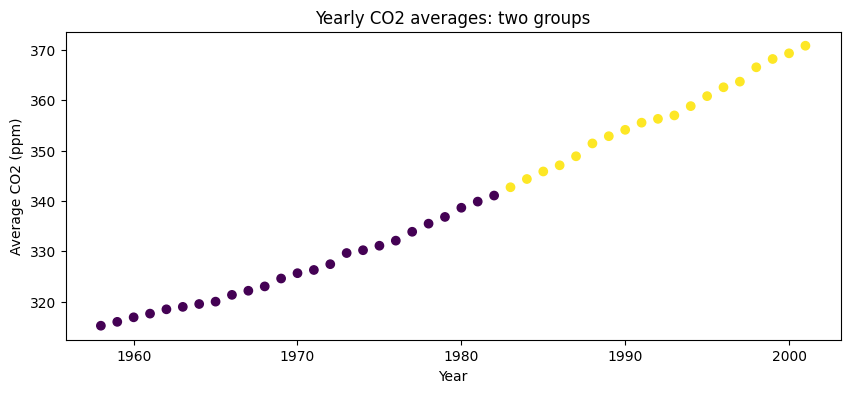

In [8]:
plt.figure(figsize=(10, 4))
plt.scatter(result["year"], result["mean_ppm"], c=result["group"])
plt.title("Yearly CO2 averages: two groups")
plt.xlabel("Year")
plt.ylabel("Average CO2 (ppm)")
plt.show()

## Your turn — Quick challenge

Change `kmeans2(values, 2, ...)` to `kmeans2(values, 3, ...)`. What changes? Do the groups explain **why** CO₂ changes?

### Before you finish

**Interpretation:** Interpolation produces estimates, not measurements. Clustering describes similarity; it does not establish causes. Yearly mean CO₂ also has a strong time trend.